In [14]:
import os
import json
import urllib.request
import urllib.parse
import requests
import pandas as pd
from requests.auth import HTTPBasicAuth
from pybliometrics.scopus import ScopusSearch
from pybliometrics.utils import create_config, init

# ==========================================
# 1. SETUP LOCAL DIRECTORY
# ==========================================
# This creates the 'MuTech/01_Raw_Exports' folder wherever you run the script
current_dir = os.getcwd()
folder_path = os.path.join(current_dir, 'MuTech', '01_Raw_Exports')
os.makedirs(folder_path, exist_ok=True)
print(f"Ready to save files locally to: {folder_path}\n")

# ==========================================
# 2. SCOPUS EXTRACTION & AUTOMATED FILTERING
# ==========================================
print("\nStarting Scopus extraction...")
try:
    init() 
except FileNotFoundError:
    print("Scopus config not found. Please run create_config() in your terminal manually.")

try:
    scopus_query = 'TITLE-ABS-KEY(("music" OR "instrument" OR "music information retrieval" OR "audio signal processing") AND ("performance" OR "solo" OR "ensemble" OR "transcription") AND ("machine learning" OR "AI" OR "artificial intelligence" OR "deep learning")) AND PUBYEAR > 2019'
    search_results = ScopusSearch(scopus_query)

    if search_results.results:
        df_scopus = pd.DataFrame(search_results.results)
        initial_count = len(df_scopus)
        
        # Automated Filtering: Keep only empirical studies (drops books/reviews)
        valid_types = ['Article', 'Conference Paper']
        df_scopus = df_scopus[df_scopus['subtypeDescription'].isin(valid_types)]
        
        # Automated Filtering: Drop rows without an abstract or authors
        df_scopus = df_scopus.dropna(subset=['description', 'creator'])
        
        # Pruning and Renaming Columns for Rayyan
        df_scopus = df_scopus[['title', 'description', 'coverDate', 'doi', 'creator', 'authkeywords', 'subtypeDescription']]
        df_scopus = df_scopus.rename(columns={
            'title': 'Title',
            'description': 'Abstract',
            'coverDate': 'Year',
            'doi': 'DOI',
            'creator': 'Authors',
            'authkeywords': 'Keywords',
            'subtypeDescription': 'Document Type'
        })
        
        # Clean the Year format
        df_scopus['Year'] = df_scopus['Year'].astype(str).str[:4]
        df_scopus['Source'] = 'Scopus'

        final_count = len(df_scopus)
        print(f"Total Scopus papers originally extracted: {initial_count}")
        print(f"Total Scopus papers kept after automated exclusion: {final_count}")
        print(f"Junk papers automatically dropped: {initial_count - final_count}")
        
        if not df_scopus.empty:
            df_scopus.to_csv(os.path.join(folder_path, 'Scopus_Filtered.csv'), index=False)
            print("Scopus filtered CSV saved successfully.")
    else:
        print("No Scopus results found or query failed.")
except Exception as e:
    print(f"Scopus extraction failed: {e}")


print("\nAll extractions complete! Check the MuTech/01_Raw_Exports folder.")

ModuleNotFoundError: No module named 'pybliometrics'

In [ ]:
import urllib.request
import urllib.parse
import json
import pandas as pd

# ==========================================
# 5. IEEE XPLORE EXTRACTION (UPDATED)
# ==========================================
print("\nStarting IEEE extraction...")
ieee_api_key = "h24uddpgdmamhmxhmgsfhzg3"

try:
    ieee_query = '("music" OR "instrument" OR "music information retrieval" OR "audio signal processing") AND ("performance" OR "solo" OR "ensemble" OR "transcription") AND ("machine learning" OR "AI" OR "artificial intelligence" OR "deep learning")'
    encoded_query = urllib.parse.quote(ieee_query)
    
    # We can use HTTPS here as well for better security
    url = f"https://ieeexploreapi.ieee.org/api/v1/search/articles?apikey={ieee_api_key}&format=json&max_records=200&querytext={encoded_query}"

    # FIX: Add Browser Headers to bypass the 403 Firewall block
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36',
        'Accept': 'application/json'
    }

    # Swap urllib for requests to easily pass headers
    response = requests.get(url, headers=headers)

    if response.status_code == 200:
        data = response.json()
        print(f"Total IEEE papers extracted: {data.get('total_records', 0)}")
        
        if 'articles' in data:
            df_ieee = pd.DataFrame(data['articles'])
            df_ieee.to_csv(os.path.join(folder_path, 'IEEE_Raw.csv'), index=False)
            print("IEEE CSV saved successfully.")
        else:
            print("No articles found in the IEEE response.")
    else:
        print(f"IEEE API blocked the request. Status Code: {response.status_code}")
        print(f"Server Response: {response.text}")

except Exception as e:
    print(f"IEEE extraction failed: {e}")


Starting IEEE extraction...
IEEE API blocked the request. Status Code: 403
Server Response: <h1>Developer Inactive</h1>


Dataset Consolidation

In [ ]:


import pandas as pd

# ==========================================================
# LOAD FILES
# ==========================================================

scopus = pd.read_csv(".\\raw_exports\\Scopus_Filtered.csv")
ieee = pd.read_csv(".\\raw_exports\\IEEE_export2026.06.08-04.08.55.csv")

# ==========================================================
# ADD SOURCE DATABASE LABEL
# ==========================================================

scopus["Source Database"] = "Scopus"
ieee["Source Database"] = "IEEE"

# ==========================================================
# STANDARDIZE SCOPUS
# ==========================================================

scopus_clean = pd.DataFrame()

scopus_clean["Title"] = scopus["Title"]
scopus_clean["Abstract"] = scopus["Abstract"]
scopus_clean["Authors"] = scopus["Authors"]
scopus_clean["Year"] = scopus["Year"]
scopus_clean["DOI"] = scopus["DOI"]
scopus_clean["Keywords"] = scopus["Keywords"]

# BUG (found during Phase 4 EDA, 2026-07): this was written assuming Scopus's "Source"
# column holds the journal/conference name. It doesn't -- the Scopus extraction cell above
# sets df_scopus['Source'] = 'Scopus' as a which-database flag (redundant with
# "Source Database" below), and the real Scopus venue field (e.g. prism:publicationName)
# was never pulled from the API in the first place. So this line was silently writing the
# literal string "Scopus" into Publication Venue for every Scopus row, not a real venue.
# Left as an explicit null instead of a misleading placeholder; a fix requires re-pulling
# Scopus with the actual venue field included, which this notebook doesn't have working
# API access to do right now (see the ModuleNotFoundError two cells up).
scopus_clean["Publication Venue"] = None

scopus_clean["Document Type"] = scopus["Document Type"]

scopus_clean["Source Database"] = "Scopus"

scopus_clean["PDF Link"] = None

# ==========================================================
# STANDARDIZE IEEE
# ==========================================================

ieee_clean = pd.DataFrame()

ieee_clean["Title"] = ieee["Document Title"]
ieee_clean["Abstract"] = ieee["Abstract"]
ieee_clean["Authors"] = ieee["Authors"]
ieee_clean["Year"] = ieee["Publication Year"]
ieee_clean["DOI"] = ieee["DOI"]

# Merge IEEE keyword fields
ieee_clean["Keywords"] = (
    ieee[
        [
            c
            for c in [
                "Author Keywords",
                "IEEE Terms",
                "Mesh_Terms"
            ]
            if c in ieee.columns
        ]
    ]
    .fillna("")
    .astype(str)
    .agg("; ".join, axis=1)
)

ieee_clean["Publication Venue"] = ieee["Publication Title"]

# Better than using Document Identifier
ieee_clean["Document Type"] = "IEEE Publication"

ieee_clean["Source Database"] = "IEEE"

ieee_clean["PDF Link"] = ieee["PDF Link"]

# ==========================================================
# MERGE DATASETS
# ==========================================================

merged = pd.concat(
    [scopus_clean, ieee_clean],
    ignore_index=True
)

# ==========================================================
# CREATE UNIQUE RECORD ID
# ==========================================================

merged["record_id"] = range(
    1,
    len(merged) + 1
)

# ==========================================================
# CLEAN TEXT FIELDS
# ==========================================================

for col in ["Title", "Abstract", "Authors", "Keywords"]:
    merged[col] = (
        merged[col]
        .fillna("")
        .astype(str)
        .str.strip()
    )

# ==========================================================
# CREATE NORMALIZED TITLE
# FOR FUTURE DEDUPLICATION
# ==========================================================

merged["Title_norm"] = (
    merged["Title"]
    .str.lower()
    .str.strip()
    .str.replace(r"[^\w\s]", "", regex=True)
)

# ==========================================================
# SAVE MERGED FILE
# ==========================================================

merged.to_csv(
    "merged_scopus_ieee.csv",
    index=False,
    encoding="utf-8-sig"
)

print(f"Total records: {len(merged)}")
print("Saved: merged_scopus_ieee.csv")

Total records: 9943
Saved: merged_scopus_ieee.csv


In [ ]:
# Initial count
initial_count = len(merged)

# ==========================================
# DOI DEDUPLICATION
# ==========================================

after_doi = merged.drop_duplicates(
    subset=["DOI"],
    keep="first"
)

doi_duplicates_removed = initial_count - len(after_doi)

# ==========================================
# TITLE DEDUPLICATION
# ==========================================

after_title = after_doi.drop_duplicates(
    subset=["Title_norm"],
    keep="first"
)

title_duplicates_removed = len(after_doi) - len(after_title)

# ==========================================
# FINAL COUNTS
# ==========================================

total_duplicates_removed = (
    doi_duplicates_removed +
    title_duplicates_removed
)

print(f"Initial records: {initial_count}")
print(f"After DOI deduplication: {len(after_doi)}")
print(f"DOI duplicates removed: {doi_duplicates_removed}")

print(f"\nAfter Title deduplication: {len(after_title)}")
print(f"Title duplicates removed: {title_duplicates_removed}")

print(f"\nTotal duplicates removed: {total_duplicates_removed}")

# Replace merged with final deduplicated dataset
merged = after_title

# ==========================================================
# SAVE DEDUPLICATED FILE
# ==========================================================

merged.to_csv(
    "merged_deduplicated.csv",
    index=False,
    encoding="utf-8-sig"
)

print(f"Total records: {len(merged)}")
print("Saved: merged_deduplicated.csv")

Initial records: 9943
After DOI deduplication: 9017
DOI duplicates removed: 926

After Title deduplication: 9007
Title duplicates removed: 10

Total duplicates removed: 936
Total records: 9007
Saved: merged_deduplicated.csv


In [ ]:
merged["search_text"] = (
    merged["Title"].fillna("") + " " +
    merged["Abstract"].fillna("") + " " +
    merged["Keywords"].fillna("")
).str.lower()

exclude_terms = [
    # Speech
    "speech recognition",
    "speaker recognition",
    "speaker verification",
    "speaker identification",
    "speech synthesis",
    "text-to-speech",
    "tts",
    "automatic speech recognition",
    "voice conversion",
    "speech enhancement",
    "speech separation",
    "spoken language",
    "dialogue system",

    # Biomedical
    "parkinson",
    "alzheimer",
    "dysphonia",
    "pathology",
    "clinical",
    "medical",
    "healthcare",
    "diagnosis",
    "disease",
    "patient",
    "biomarker",
    "hospital",

    # Recommendation
    "recommender system",
    "playlist generation",
    "playlist continuation",
    "user preference",
    "collaborative filtering",
    "music discovery",
    "consumer behavior",
    "listening preference",

    # Industry / Business
    "music marketing",
    "licensing",
    "streaming platform",
    "music consumption",
    "music popularity",
    "chart prediction",
    "social media",
    "music industry",

    # Education / Psychology
    "emotion perception",
    "music cognition",
    "listener study",
    "perceptual study",
    "survey study",
    "questionnaire",

    # Musicology
    "historical music analysis",
    "music evolution",
    "style evolution",
    "musicology",

    # Metadata-focused
    "metadata tagging",
    "artist tagging"
    
    "semantic tagging",
    "genre tagging"
    
    "hearing aid",
    "cochlear implant",
    "audiology",
    "hearing loss",
    "hearing impairment"
    
    "music generation",
    "music therapy",
    "mood detection"
]

mask = merged["search_text"].apply(
    lambda x: any(term in x for term in exclude_terms)
)

filtered = merged[~mask]

print("excluded based on exclude terms:", mask.sum())



C:\Users\mnari\AppData\Local\Temp\ipykernel_48424\223032608.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merged["search_text"] = (


excluded based on exclude terms: 2829


In [ ]:
def find_matching_term(text, terms):
    for term in terms:
        if term in text:
            return term
    return ""

merged["Exclude_Reason"] = merged["search_text"].apply(
    lambda x: find_matching_term(x, exclude_terms)
)

C:\Users\mnari\AppData\Local\Temp\ipykernel_48424\1925527746.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merged["Exclude_Reason"] = merged["search_text"].apply(


In [ ]:
priority_terms = [
    "music information retrieval",
    "mir",
    "music retrieval",
    "music classification",
    "genre classification",
    "music tagging",
    "music transcription",
    "automatic music transcription",
    "source separation",
    "music source separation",
    "singing voice",
    "singing",
    "choral",
    "choir",
    "ensemble",
    "instrumental",
    "pitch estimation",
    "pitch detection",
    "music similarity",
    "audio tagging",
    "music emotion recognition",
    "score following",
    "optical music recognition",
    "omr"
]

In [ ]:
def contains_any(text, terms):
    return any(term in text for term in terms)

merged["Priority_Flag"] = merged["search_text"].apply(
    lambda x: contains_any(x, priority_terms)
)

merged["Exclude_Flag"] = merged["search_text"].apply(
    lambda x: contains_any(x, exclude_terms)
)



C:\Users\mnari\AppData\Local\Temp\ipykernel_48424\2552450553.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merged["Priority_Flag"] = merged["search_text"].apply(
C:\Users\mnari\AppData\Local\Temp\ipykernel_48424\2552450553.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  merged["Exclude_Flag"] = merged["search_text"].apply(


In [ ]:
priority_df = merged[
    merged["Priority_Flag"]
].copy()

In [ ]:
excluded_df = merged[
    merged["Exclude_Flag"]
].copy()

In [ ]:
remaining_df = merged[
    (~merged["Priority_Flag"]) &
    (~merged["Exclude_Flag"])
].copy()

In [ ]:
priority_df.to_csv(
    "./output/priority_records.csv",
    index=False,
    encoding="utf-8-sig"
)


excluded_df.to_csv(
    "./output/excluded_records.csv",
    index=False,
    encoding="utf-8-sig"
)

remaining_df.to_csv(
    "./output/remaining_records.csv",
    index=False,
    encoding="utf-8-sig"
)

In [ ]:
print(f"Total records: {len(merged):,}")
print(f"Priority records: {len(priority_df):,}")
print(f"Excluded records: {len(excluded_df):,}")
print(f"Remaining records: {len(remaining_df):,}")

Total records: 9,007
Priority records: 1,728
Excluded records: 3,084
Remaining records: 4,710


In [ ]:
official = pd.read_csv(
    r".\raw_exports\CITE4D_Official_Papers.csv"
)

official["Title_norm"] = (
    official["TOPIC"]
    .fillna("")
    .str.lower()
    .str.strip()
    .str.replace(r"[^\w\s]", "", regex=True)
)

duplicates = merged.merge(
    official[
        [
            "TOPIC",
            "AUTHOR",
            "YEAR",
            "APA FORMAT",
            "Title_norm"
        ]
    ],
    on="Title_norm",
    how="inner"
)

duplicates.to_csv(
    "./output/official_paper_matches.csv",
    index=False,
    encoding="utf-8-sig"
)

print(f"Matches found: {len(duplicates)}")
print("Saved: output/official_paper_matches.csv")



In [ ]:
new_candidates = merged[
    ~merged["Title_norm"].isin(
        official["Title_norm"]
    )
]

new_candidates.to_csv(
    "./output/new_candidates.csv",
    index=False
)

print(f"New candidates: {len(new_candidates)}")

## Synthesis & Social Network Analysis (SNA) Visualization

In [15]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from itertools import combinations
from collections import Counter

# ====================================================
# LOAD PRIORITY RECORDS
# ====================================================

df = pd.read_csv(
    r".\output\priority_records.csv",
    encoding="utf-8-sig"
)

print(f"Loaded {len(df):,} priority records")
print(f"Columns: {df.columns.tolist()}")


Loaded 1,728 priority records
Columns: ['Title', 'Abstract', 'Authors', 'Year', 'DOI', 'Keywords', 'Publication Venue', 'Document Type', 'Source Database', 'PDF Link', 'record_id', 'Title_norm', 'search_text', 'Exclude_Reason', 'Priority_Flag', 'Exclude_Flag']


In [16]:
# ====================================================
# PARSE KEYWORDS
# Scopus uses " | ", IEEE uses ";"
# ====================================================

def parse_keywords(kw_str):
    if pd.isna(kw_str) or str(kw_str).strip() == "":
        return []
    kw_str = str(kw_str).replace(" | ", ";").replace("|", ";")
    return [
        k.strip().lower()
        for k in kw_str.split(";")
        if k.strip()
    ]

df["kw_list"] = df["Keywords"].apply(parse_keywords)

all_kw  = [k for kl in df["kw_list"] for k in kl]
kw_freq = Counter(all_kw)

print(f"Records with keywords : {df['kw_list'].apply(bool).sum():,} / {len(df):,}")
print(f"Total keyword tokens  : {len(all_kw):,}")
print("\nTop 20 keywords:")
for kw, cnt in kw_freq.most_common(20):
    print(f"  {cnt:4d}  {kw}")


Records with keywords : 1,624 / 1,728
Total keyword tokens  : 10,060

Top 20 keywords:
   404  machine learning
   396  deep learning
   219  music information retrieval
   105  ensemble learning
   102  music
    88  artificial intelligence
    83  feature extraction
    77  music genre classification
    66  convolutional neural networks
    58  neural networks
    53  random forest
    53  convolutional neural network
    51  cnn
    47  transfer learning
    47  training
    43  classification
    43  automatic music transcription
    39  music emotion recognition
    39  accuracy
    36  music source separation


In [17]:
# ====================================================
# BUILD KEYWORD CO-OCCURRENCE GRAPH
# ====================================================

MIN_COOCCURRENCE = 3   # raise to declutter, lower to show more edges
TOP_N_KEYWORDS   = 80  # max nodes for readability

edge_counter = Counter()
for kw_list in df["kw_list"]:
    unique_kws = list(set(kw_list))
    for pair in combinations(sorted(unique_kws), 2):
        edge_counter[pair] += 1

G_kw = nx.Graph()
for (kw1, kw2), weight in edge_counter.items():
    if weight >= MIN_COOCCURRENCE:
        G_kw.add_edge(kw1, kw2, weight=weight)

G_kw.remove_nodes_from(list(nx.isolates(G_kw)))

# Keep only the top-N nodes by degree
top_nodes = {n for n, _ in sorted(G_kw.degree(), key=lambda x: -x[1])[:TOP_N_KEYWORDS]}
G_kw = G_kw.subgraph(top_nodes).copy()

print(f"Keyword network  →  nodes: {G_kw.number_of_nodes()},  edges: {G_kw.number_of_edges()}")


Keyword network  →  nodes: 80,  edges: 493


In [18]:
# ====================================================
# COMMUNITY DETECTION (colors each cluster)
# ====================================================

communities = list(nx.community.greedy_modularity_communities(G_kw))
node_community = {}
for i, community in enumerate(communities):
    for node in community:
        node_community[node] = i

print(f"Found {len(communities)} keyword communities")
for i, c in enumerate(communities[:6]):
    top = sorted(c, key=lambda n: G_kw.degree(n), reverse=True)[:5]
    print(f"  Cluster {i+1}: {", ".join(top)}")


Found 5 keyword communities
  Cluster 1: deep learning, music, feature extraction, training, multiple signal classification
  Cluster 2: machine learning, ensemble learning, music genre classification, support vector machines, random forest
  Cluster 3: protocols, artificial intelligence, http, recommender systems, filtering
  Cluster 4: music information retrieval, convolutional neural networks, data models, computational modeling, predictive models
  Cluster 5: accuracy, transformers, modeling, printing


C:\Users\Yesha\AppData\Local\Temp\ipykernel_7252\3671435573.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap        = cm.get_cmap("tab20", len(communities))


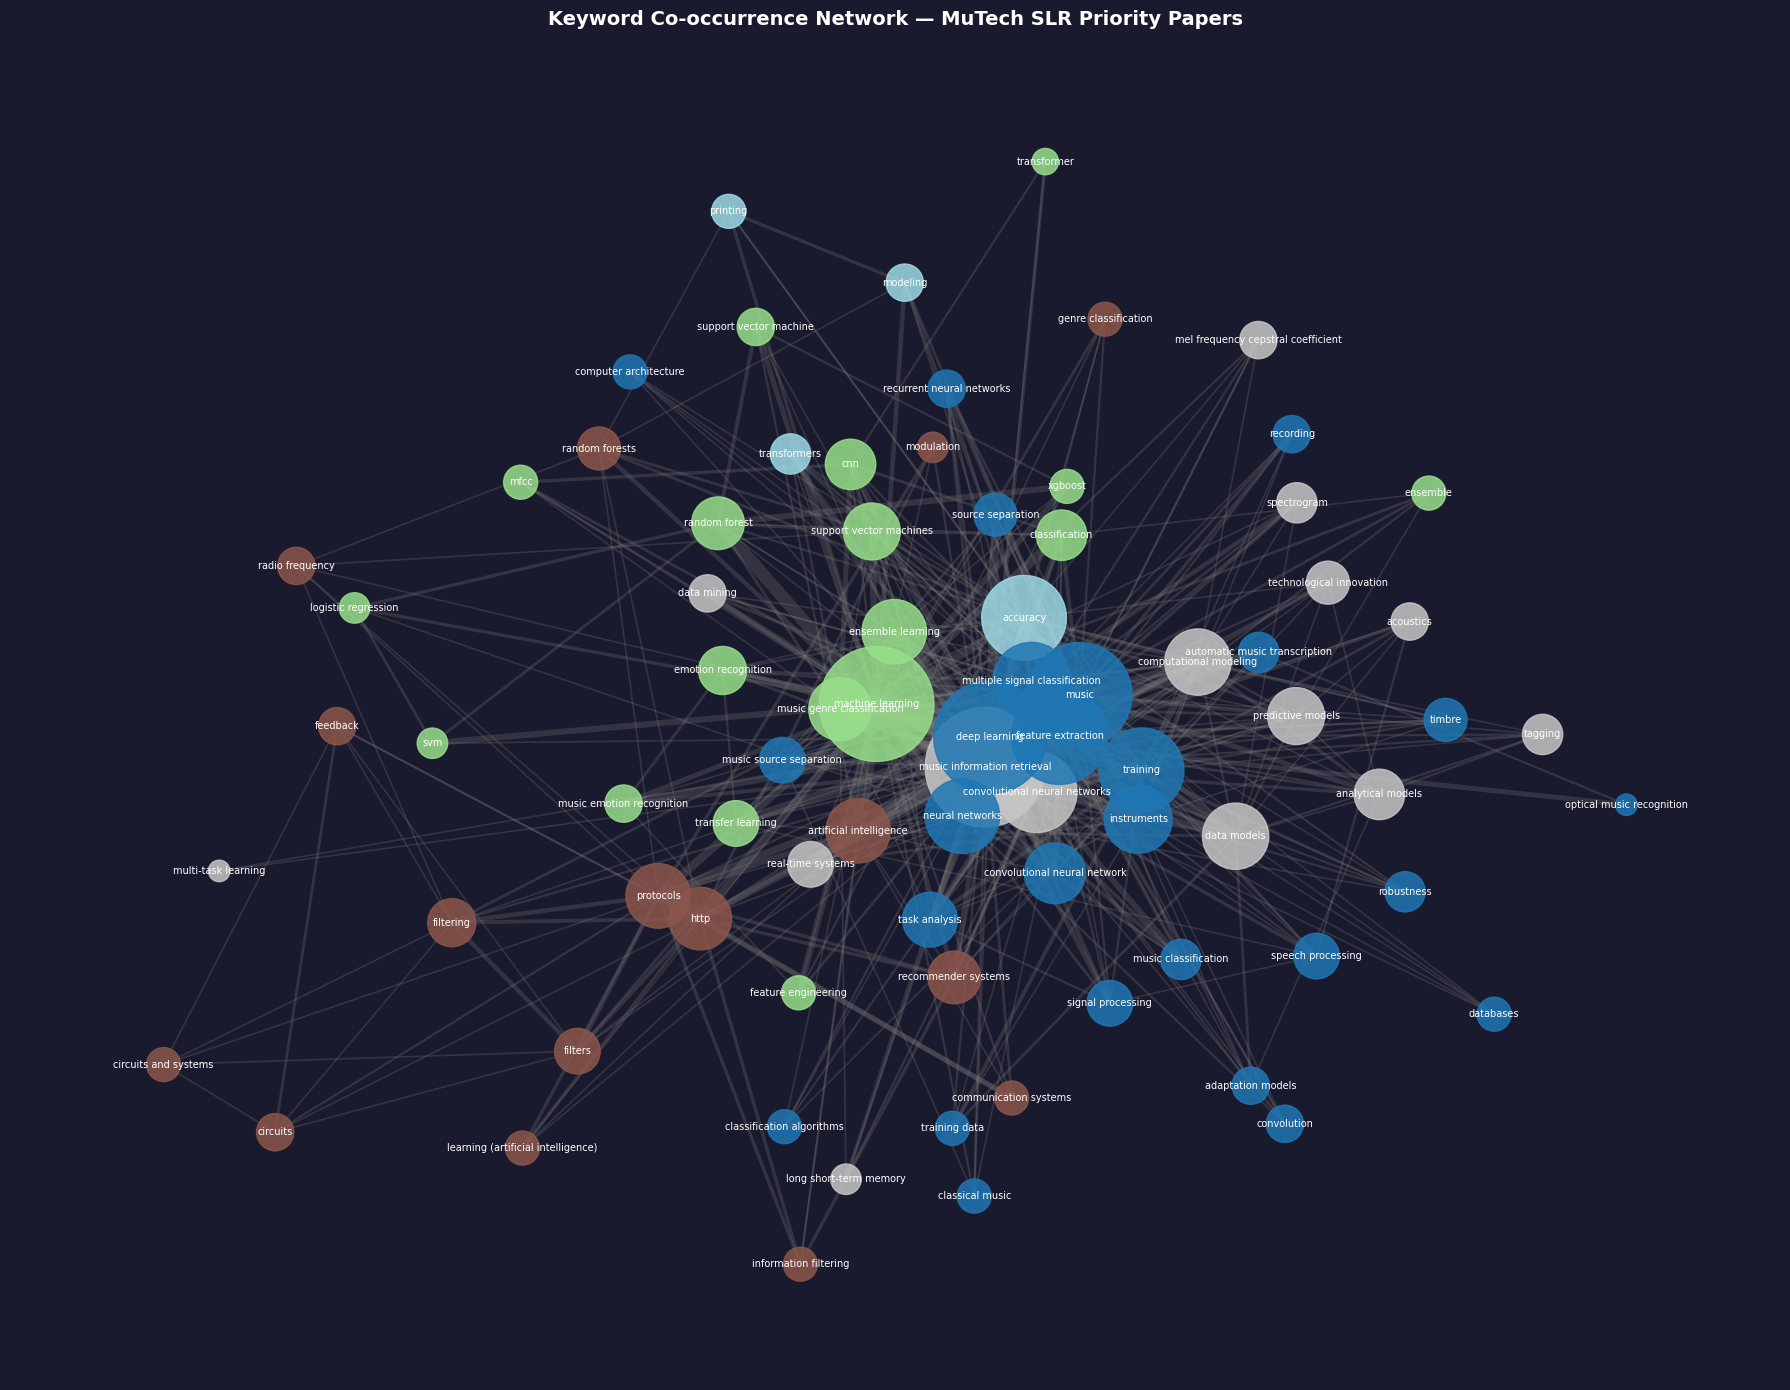

Saved: MuTech/keyword_cooccurrence_network.png


In [19]:
# ====================================================
# STATIC KEYWORD CO-OCCURRENCE PLOT
# ====================================================

fig, ax = plt.subplots(figsize=(18, 14))

pos         = nx.spring_layout(G_kw, k=1.2, seed=42)
degrees     = dict(G_kw.degree())
node_sizes  = [degrees[n] * 120 for n in G_kw.nodes()]
edge_widths = [G_kw[u][v]["weight"] * 0.4 for u, v in G_kw.edges()]
cmap        = cm.get_cmap("tab20", len(communities))
colors      = [cmap(node_community[n]) for n in G_kw.nodes()]

nx.draw_networkx_nodes(G_kw, pos, node_size=node_sizes,
                       node_color=colors, alpha=0.85, ax=ax)
nx.draw_networkx_edges(G_kw, pos, width=edge_widths,
                       alpha=0.25, edge_color="grey", ax=ax)
nx.draw_networkx_labels(G_kw, pos, font_size=7,
                        font_color="white", ax=ax)

ax.set_title("Keyword Co-occurrence Network — MuTech SLR Priority Papers",
             fontsize=14, fontweight="bold", pad=15, color="white")
ax.axis("off")
fig.patch.set_facecolor("#1a1a2e")
ax.set_facecolor("#1a1a2e")
plt.tight_layout()
plt.savefig(
    r".\output\keyword_cooccurrence_network.png",
    dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor()
)
plt.show()
print("Saved: output/keyword_cooccurrence_network.png")


In [21]:
# ====================================================
# INTERACTIVE KEYWORD NETWORK (pyvis → HTML)
# Open the saved HTML file in your browser
# ====================================================

from pyvis.network import Network

palette = [
    "#e63946","#457b9d","#2a9d8f","#e9c46a","#f4a261",
    "#a8dadc","#8ecae6","#06d6a0","#ef476f","#ffd166",
    "#118ab2","#073b4c","#b5838d","#6d6875","#c77dff",
    "#48cae4","#80b918","#ff6b6b","#4ecdc4","#ffe66d",
]

net = Network(
    height="720px", width="100%",
    bgcolor="#1a1a2e", font_color="white",
    notebook=True, cdn_resources="in_line"
)
net.from_nx(G_kw)

for node in net.nodes:
    nid         = node["id"]
    deg         = G_kw.degree(nid)
    com         = node_community.get(nid, 0)
    node["size"]  = deg * 6 + 8
    node["color"] = palette[com % len(palette)]
    node["title"] = f"{nid}\nConnections: {deg}"

net.set_options("""
var options = {
  "physics": {
    "barnesHut": {
      "gravitationalConstant": -12000,
      "centralGravity": 0.3,
      "springLength": 160
    }
  },
  "interaction": { "hover": true, "tooltipDelay": 100 }
}
""")

out_html = r".\output\keyword_network_interactive.html"
net.write_html(out_html)
print(f"Interactive network saved → {out_html}")
print("Open that file in your browser to explore.")

from IPython.display import IFrame
IFrame(out_html, width="100%", height=750)


UnicodeEncodeError: 'charmap' codec can't encode characters in position 263607-263621: character maps to <undefined>

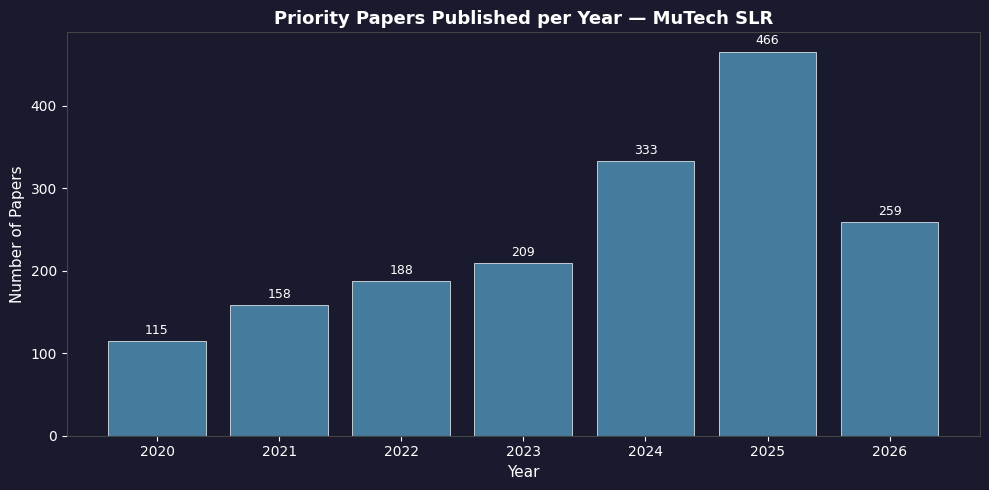

Saved: MuTech/publication_trend.png


In [22]:
# ====================================================
# PUBLICATION TREND BY YEAR
# ====================================================

year_counts = (
    df["Year"]
    .astype(str).str[:4]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(year_counts.index, year_counts.values,
              color="#457b9d", edgecolor="white", linewidth=0.5)
ax.bar_label(bars, padding=3, fontsize=9, color="white")
ax.set_xlabel("Year", fontsize=11, color="white")
ax.set_ylabel("Number of Papers", fontsize=11, color="white")
ax.set_title("Priority Papers Published per Year — MuTech SLR",
             fontsize=13, fontweight="bold", color="white")
ax.tick_params(colors="white")
ax.spines[:].set_color("#444")
fig.patch.set_facecolor("#1a1a2e")
ax.set_facecolor("#1a1a2e")
plt.tight_layout()
plt.savefig(
    r".\output\publication_trend.png",
    dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor()
)
plt.show()
print("Saved: output/publication_trend.png")


In [23]:
# ====================================================
# CO-AUTHORSHIP NETWORK
# ====================================================

def parse_authors(author_str):
    if pd.isna(author_str) or str(author_str).strip() == "":
        return []
    return [a.strip() for a in str(author_str).split(";") if a.strip()]

df["author_list"] = df["Authors"].apply(parse_authors)

auth_edge_counter = Counter()
for authors in df["author_list"]:
    unique_authors = list(set(authors))
    if len(unique_authors) < 2:
        continue
    for pair in combinations(sorted(unique_authors), 2):
        auth_edge_counter[pair] += 1

G_auth = nx.Graph()
for (a1, a2), weight in auth_edge_counter.items():
    G_auth.add_edge(a1, a2, weight=weight)

# Keep top 60 most-connected authors
top_authors = {n for n, _ in sorted(G_auth.degree(), key=lambda x: -x[1])[:60]}
G_auth_top  = G_auth.subgraph(top_authors).copy()
G_auth_top.remove_nodes_from(list(nx.isolates(G_auth_top)))

print(f"Co-authorship network → nodes: {G_auth_top.number_of_nodes()},  edges: {G_auth_top.number_of_edges()}")
print("\nTop 15 most collaborative authors:")
for author, deg in sorted(G_auth.degree(), key=lambda x: -x[1])[:15]:
    print(f"  {deg:3d}  {author}")


Co-authorship network → nodes: 60,  edges: 205

Top 15 most collaborative authors:
   20  Y. Zhang
   17  J. Li
   16  H. Zhang
   15  E. Benetos
   15  D. Jeong
   15  S. Lui
   14  Y. Li
   12  X. Serra
   12  H. Zhu
   11  W. Li
   11  W. -H. Liao
   11  W. Choi
   11  Y. Mitsufuji
   11  X. Wang
   11  X. Li


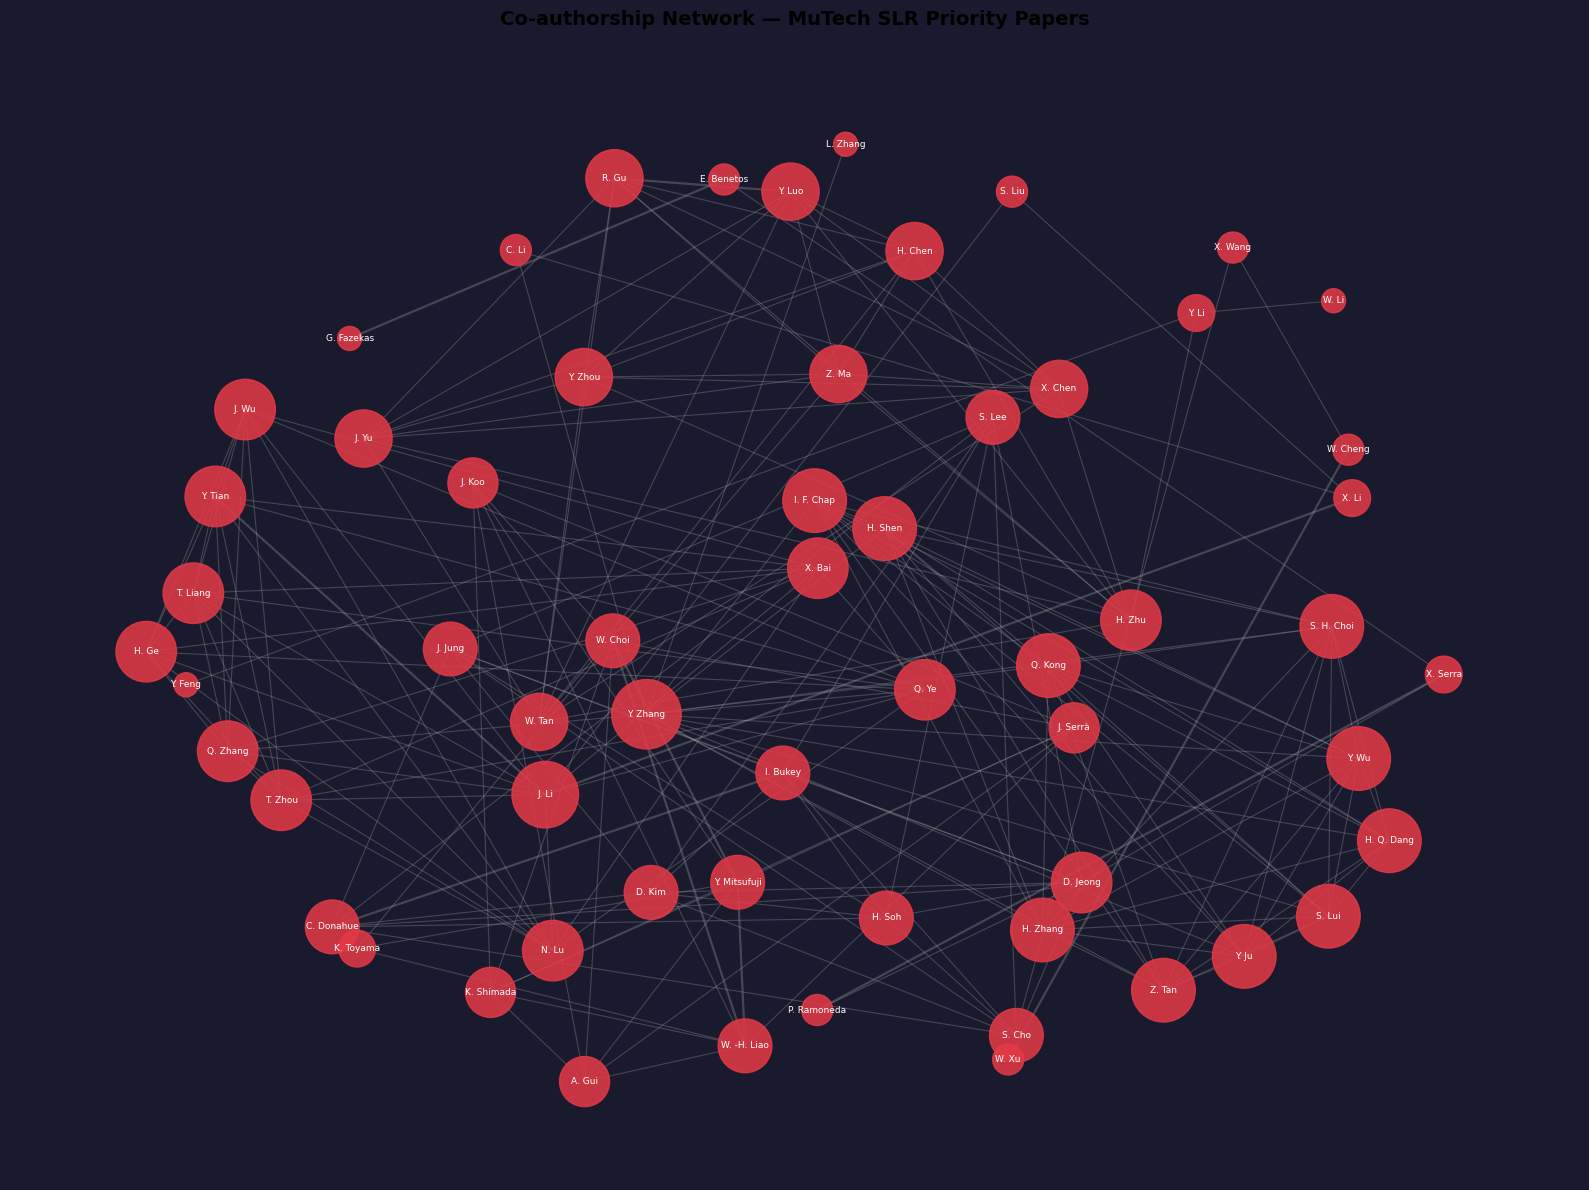

Saved: MuTech/coauthorship_network.png


In [ ]:
# ====================================================
# CO-AUTHORSHIP PLOT
# ====================================================

fig, ax = plt.subplots(figsize=(16, 12))

pos_auth        = nx.spring_layout(G_auth_top, k=1.5, seed=7)
auth_degrees    = dict(G_auth_top.degree())
auth_node_sizes = [auth_degrees[n] * 200 + 100 for n in G_auth_top.nodes()]
auth_edge_w     = [G_auth_top[u][v]["weight"] * 0.8 for u, v in G_auth_top.edges()]

nx.draw_networkx_nodes(G_auth_top, pos_auth,
                       node_size=auth_node_sizes,
                       node_color="#e63946", alpha=0.85, ax=ax)
nx.draw_networkx_edges(G_auth_top, pos_auth,
                       width=auth_edge_w, alpha=0.3,
                       edge_color="#aaaaaa", ax=ax)
nx.draw_networkx_labels(G_auth_top, pos_auth,
                        font_size=6.5, font_color="white", ax=ax)

ax.set_title("Co-authorship Network — MuTech SLR Priority Papers",
             fontsize=14, fontweight="bold", pad=15, color="white")
ax.axis("off")
fig.patch.set_facecolor("#1a1a2e")
ax.set_facecolor("#1a1a2e")
plt.tight_layout()
plt.savefig(
    r".\output\coauthorship_network.png",
    dpi=150, bbox_inches="tight", facecolor=fig.get_facecolor()
)
plt.show()
print("Saved: output/coauthorship_network.png")


In [25]:
# ====================================================
# EXPORT TOP KEYWORDS TABLE
# ====================================================

top_kw_df = pd.DataFrame(
    kw_freq.most_common(50),
    columns=["Keyword", "Frequency"]
)
top_kw_df.to_csv(
    r".\output\top_keywords.csv",
    index=False, encoding="utf-8-sig"
)

print("Top 50 keywords saved → output/top_keywords.csv")
print(top_kw_df.head(20).to_string(index=False))


Top 50 keywords saved → MuTech/top_keywords.csv
                      Keyword  Frequency
             machine learning        404
                deep learning        396
  music information retrieval        219
            ensemble learning        105
                        music        102
      artificial intelligence         88
           feature extraction         83
   music genre classification         77
convolutional neural networks         66
              neural networks         58
                random forest         53
 convolutional neural network         53
                          cnn         51
            transfer learning         47
                     training         47
               classification         43
automatic music transcription         43
    music emotion recognition         39
                     accuracy         39
      music source separation         36
